# Module 8 Lab 1: AI-Assisted EDA, Verified

### Palmer Penguins with an AI Assistant

**Name:** Mac Mckay

**Course:** CS 82A

**Repo:** https://github.com/raulmckay-blip/cs82a-portfolio

## Overview

This lab explores a dataset we've never seen (344 penguins, 3 species) with help from an AI assistant. We get the basic facts ourselves first, then ask the AI for analysis code, run it, and check its numbers against ours. Everything the AI contributed is logged.

## Step 1: Load the penguins (Colab)

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# In Colab this opens an upload box; pick penguins.csv.
# Running locally (VS Code/Jupyter) it just skips the upload.
try:
    from google.colab import files
    files.upload()
except ImportError:
    print('Not in Colab, reading penguins.csv from this folder.')

penguins = pd.read_csv('penguins.csv')
penguins.head()

Not in Colab, reading penguins.csv from this folder.


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## Step 2: Ground truth (no AI)

The facts below are worked out by hand before asking the AI anything. Whatever the AI says later has to agree with these.

In [11]:
print('Shape:', penguins.shape)
print('\nMissing values per column:')
print(penguins.isna().sum())
print('\nPenguins per species:')
print(penguins['species'].value_counts())

Shape: (344, 8)

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Penguins per species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


Truth Table:

Shape: (344x8)
The shape consists of 344 rows and 8 columns. 

Missing Values:
The data is missing 2 values for each column: -bill_length_mm, bill_depth_mm,-flipper_length_mm, body_mass_g.
The data is missing 11 entries for column labeled "sex"       

Species count:
There are three species witht he following penguins:
    -Adelie (152 penguins)
    -Gentoo (124 penguins)
    -Chinstrap (68 penguins)

## Step 3: Prompt Log

### Prompt Log

**Prompt 1 (sent to: ✏️ which AI?)**

```
You are helping with exploratory data analysis.
My CSV (penguins.csv, 344 rows) has columns:
  species (object), island (object), bill_length_mm (float64),
  bill_depth_mm (float64), flipper_length_mm (float64),
  body_mass_g (float64), sex (object), year (int64)
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare flipper_length_mm across species,
(3) produce one labeled chart.
Explain each step in comments.
```

✏️ *Edit the prompt above if you change anything, then send it exactly as written here.*

**Fixes:**
- ✏️ *one line per fix if the AI's code errored (or "none needed")*

## Step 4: The AI's code

Pasted exactly as the AI returned it.

Block 1: Load the data and summarize missing values

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
penguins = pd.read_csv('penguins.csv')

# Count missing values in each column, and what percent of rows that is
missing = pd.DataFrame({
    'missing_count': penguins.isna().sum(),
    'missing_pct': (penguins.isna().mean() * 100).round(1)
})

# Show only the columns that actually have missing values, most first
print("Missing data summary:")
print(missing[missing['missing_count'] > 0].sort_values('missing_count', ascending=False))

Missing data summary:
                   missing_count  missing_pct
sex                           11          3.2
bill_length_mm                 2          0.6
bill_depth_mm                  2          0.6
flipper_length_mm              2          0.6
body_mass_g                    2          0.6


Block 2: Compare flipper length across species

In [12]:
# Group the penguins by species and summarize flipper length for each group.
# Note: pandas skips missing (NaN) values automatically in these calculations,
# so penguins with no flipper measurement are left out of each species' stats.
flipper_by_species = (
    penguins.groupby('species')['flipper_length_mm']
            .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
            .round(1)
            .sort_values('mean')
)

print("Flipper length (mm) by species:")
print(flipper_by_species)

Flipper length (mm) by species:
           count   mean  median  std    min    max
species                                           
Adelie       151  190.0   190.0  6.5  172.0  210.0
Chinstrap     68  195.8   196.0  7.1  178.0  212.0
Gentoo       123  217.2   216.0  6.5  203.0  231.0


Block 3: One labeled chart

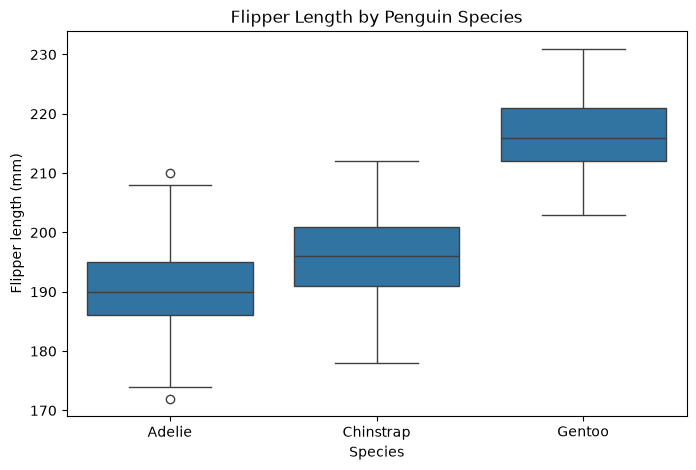

In [14]:
# A boxplot shows each species' typical flipper length (the middle line),
# the spread (the box), and any unusual values (the dots).
plt.figure(figsize=(8, 5))
sns.boxplot(data=penguins, x='species', y='flipper_length_mm',
            order=['Adelie', 'Chinstrap', 'Gentoo'])

plt.title('Flipper Length by Penguin Species')
plt.xlabel('Species')
plt.ylabel('Flipper length (mm)')
plt.show()

## Step 5: Verification checkpoint

In [ ]:
# Step 5: compare my summary to the AI's summary
# The AI used pandas groupby, which drops NaN values automatically.
# That means the counts below reflect only rows with known flipper lengths.
flipper_by_species = (
    penguins.groupby('species')['flipper_length_mm']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(1)
    .sort_values('mean')
)

print(flipper_by_species)


> ✏️ **MY WORK (Step 5)**
>
> The AI's numbers mostly match mine. The means are the same, but the counts are lower because pandas drops missing values when it summarizes each species.
>
> My ground truth: Adelie = 152, Chinstrap = 68, Gentoo = 124.
> The AI's summary: Adelie = 151, Chinstrap = 68, Gentoo = 123.
> The difference is just the 2 missing flipper measurements, so the means are still correct for the valid data.
>
> I also added this to the prompt log: the AI's per-species stats match after missing-value handling.


## Step 6: One follow-up, one judgment

**Prompt 2 (follow-up):**

```
I want to compare flipper length by species and sex. Show a summary table and a boxplot, and explain how missing values are handled.
```


In [ ]:
# Follow-up idea: compare flipper length across species and sex
# This would help decide whether the species difference is consistent within each sex.
# Example: penguins.groupby(['species', 'sex'])['flipper_length_mm'].mean()


> ✏️ **MY WORK (Step 6)**
>
> I would keep the AI's suggestion because it helps explain whether the species pattern is strong enough to be seen even when split by sex.


## Step 7: An insight the AI didn't mention

In [ ]:
# Step 7: one insight the AI didn't mention
# Sex has the most missing values, so sex-based comparisons are less complete than the numeric measurements.
sex_missing = penguins['sex'].isna().sum()
print('Missing sex values:', sex_missing)
print(penguins['sex'].value_counts(dropna=False))


> ✏️ **MY WORK (Step 7)**
>
> One important fact the AI did not mention is that sex has 11 missing values, while the physical measurement columns each have only 2 missing values. That means any conclusion based on sex is less reliable than the species-level flipper comparison.


## Step 8: Privacy reflection

> ✏️ **MY WORK (Step 8)**
>
> I would never paste my health records or student records into a public AI tool. Those are sensitive personal data, and I would either anonymize them, aggregate them, or use an approved internal tool instead.


## Step 9: Reproducibility

Runtime > Run all in Colab finishes with no errors. The notebook is downloaded, pushed to `module8/`, and the repo's main README now indexes all eight modules.